# Практика 17. Проста лінійна регресія

**Студент:** Huz_Yurii  
**Група:** IT-41  
**Варіант:** N=3, Одеса

Мета: побудувати просту лінійну регресію витрат на опалення за середньомісячною температурою, оцінити її за залишками та R² і обережно інтерпретувати прогноз.

## Дані варіанта

Температури Одеси та генерація похідних стовпців відповідають умовам практики 16/17. Фіксований seed забезпечує відтворюваність набору.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import linregress, pearsonr

np.random.seed(3)
city = "Одеса"
monthly_temp = [-1, 0, 4, 10, 16, 20, 23, 22, 17, 11, 5, 1]
months = ["Січ", "Лют", "Бер", "Кві", "Тра", "Чер", "Лип", "Сер", "Вер", "Жов", "Лис", "Гру"]

rows = []
for month, temp in zip(months, monthly_temp):
    heating_days = np.clip(18 - temp + np.random.normal(0, 1.5), 0, 30)
    heating_days = round(heating_days)
    cost = 0.15 * heating_days + np.random.normal(0, 1.0)
    cost = round(max(cost, 0), 1)
    rows.append({
        "місто": city,
        "місяць": month,
        "температура": temp,
        "опалювальні_дні": heating_days,
        "витрати_на_опалення": cost,
    })

climate = pd.DataFrame(rows)
display(climate)

,місто,місяць,температура,опалювальні_дні,витрати_на_опалення
0,Одеса,Січ,-1,22,3.7
1,Одеса,Лют,0,18,0.8
2,Одеса,Бер,4,14,1.7
3,Одеса,Кві,10,8,0.6
4,Одеса,Тра,16,2,0.0
5,Одеса,Чер,20,0,0.9
6,Одеса,Лип,23,0,1.7
7,Одеса,Сер,22,0,0.0
8,Одеса,Вер,17,0,0.0
9,Одеса,Жов,11,8,0.1


## Завдання 1. Регресійна модель

Оцінюємо модель `витрати ≈ b0 + b1 × температура`. Нахил вимірюється в умовних тис. грн на 1°C, а перетин — у тих самих одиницях витрат при 0°C. Інтерпретація перетину може бути суто формальною.

In [7]:
temperature = climate["температура"].to_numpy(dtype=float)
heating_cost = climate["витрати_на_опалення"].to_numpy(dtype=float)
result = linregress(temperature, heating_cost)
predicted = result.intercept + result.slope * temperature
residuals = heating_cost - predicted

print(f"Рівняння: витрати ≈ {result.intercept:.3f} + ({result.slope:.3f}) × температура")
print(f"b0 = {result.intercept:.3f} умовних тис. грн; b1 = {result.slope:.3f} умовних тис. грн/°C")
print(f"При підвищенні температури на 1°C очікувані витрати в середньому змінюються на {result.slope:.3f} умовних тис. грн.")
print("Знак нахилу узгоджується з очікуванням: вища температура пов'язана з нижчими витратами." if result.slope < 0 else "Знак нахилу додатний; це не відповідає очікуваному спадному зв'язку, тому слід врахувати малу вибірку та шум.")

Рівняння: витрати ≈ 2.062 + (-0.084) × температура
b0 = 2.062 умовних тис. грн; b1 = -0.084 умовних тис. грн/°C
При підвищенні температури на 1°C очікувані витрати в середньому змінюються на -0.084 умовних тис. грн.
Знак нахилу узгоджується з очікуванням: вища температура пов'язана з нижчими витратами.


## Завдання 2. Коефіцієнт детермінації

Порівнюємо два обчислення R²: квадрат кореляції з `linregress` і формулу через суму квадратів залишків та загальну суму квадратів. Для простої лінійної регресії з перетином R² має дорівнювати квадрату коефіцієнта Пірсона для тієї самої пари змінних.

In [3]:
ss_residual = np.sum(residuals ** 2)
ss_total = np.sum((heating_cost - np.mean(heating_cost)) ** 2)
r2_from_sums = 1 - ss_residual / ss_total
r2_from_linregress = result.rvalue ** 2
pearson_result = pearsonr(temperature, heating_cost)
r2_from_pearson = pearson_result.statistic ** 2

print(f"SS залишків = {ss_residual:.6f}; SS загальна = {ss_total:.6f}")
print(f"R² через linregress.rvalue² = {r2_from_linregress:.6f}")
print(f"R² через 1 - SSзалишків / SSзагальна = {r2_from_sums:.6f}")
print(f"r² з Практики 16 (pearsonr) = {r2_from_pearson:.6f}")
assert np.isclose(r2_from_linregress, r2_from_sums)
assert np.isclose(r2_from_linregress, r2_from_pearson)
print(f"Інтерпретація: температура пояснює {100 * r2_from_linregress:.1f}% вибіркового розкиду витрат; {100 * (1 - r2_from_linregress):.1f}% залишається непоясненим цією моделлю.")

SS залишків = 10.486506; SS загальна = 16.526667
R² через linregress.rvalue² = 0.365480
R² через 1 - SSзалишків / SSзагальна = 0.365480
r² з Практики 16 (pearsonr) = 0.365480
Інтерпретація: температура пояснює 36.5% вибіркового розкиду витрат; 63.5% залишається непоясненим цією моделлю.


## Завдання 3. Залишки й адекватність моделі

Залишок дорівнює фактичним мінус передбачені витрати. Перша панель показує спостереження та пряму регресії, друга — залишки відносно температури й горизонталь нульового залишку.

,місяць,температура,витрати_на_опалення,передбачені_витрати,залишок
0,Січ,-1,3.7,2.146,1.554
1,Лют,0,0.8,2.062,-1.262
2,Бер,4,1.7,1.726,-0.026
3,Кві,10,0.6,1.223,-0.623
4,Тра,16,0.0,0.719,-0.719
5,Чер,20,0.9,0.383,0.517
6,Лип,23,1.7,0.131,1.569
7,Сер,22,0.0,0.215,-0.215
8,Вер,17,0.0,0.635,-0.635
9,Жов,11,0.1,1.139,-1.039


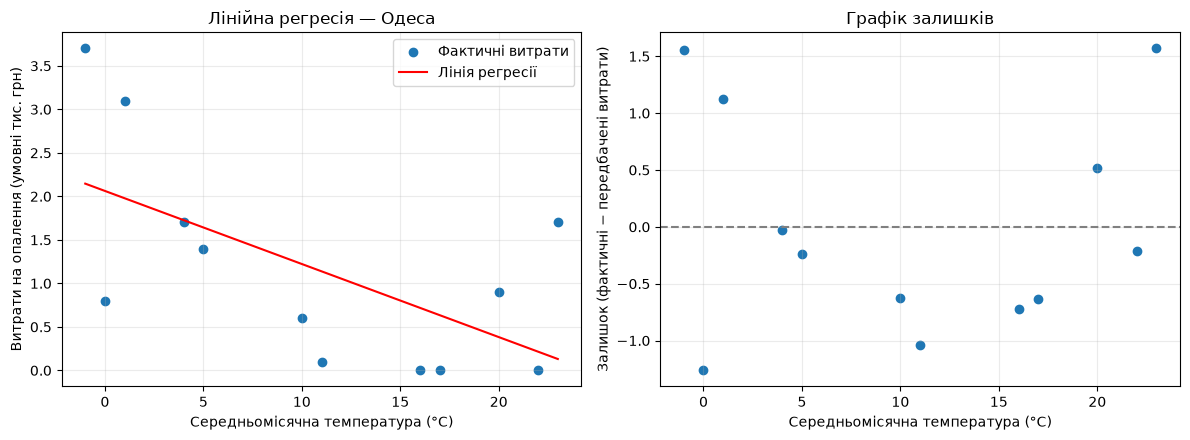

Най тепліші місяці (T ≥ 20°C):


,місяць,температура,витрати_на_опалення,передбачені_витрати,залишок
5,Чер,20,0.9,0.383,0.517
6,Лип,23,1.7,0.131,1.569
7,Сер,22,0.0,0.215,-0.215


In [4]:
climate["передбачені_витрати"] = predicted
climate["залишок"] = residuals
display(climate[["місяць", "температура", "витрати_на_опалення", "передбачені_витрати", "залишок"]].round(3))

line_x = np.linspace(temperature.min(), temperature.max(), 200)
line_y = result.intercept + result.slope * line_x
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
ax1.scatter(temperature, heating_cost, label="Фактичні витрати")
ax1.plot(line_x, line_y, color="red", label="Лінія регресії")
ax1.set_xlabel("Середньомісячна температура (°C)")
ax1.set_ylabel("Витрати на опалення (умовні тис. грн)")
ax1.set_title("Лінійна регресія — Одеса")
ax1.legend()
ax1.grid(alpha=0.25)
ax2.scatter(temperature, residuals)
ax2.axhline(0, color="gray", linestyle="--")
ax2.set_xlabel("Середньомісячна температура (°C)")
ax2.set_ylabel("Залишок (фактичні − передбачені витрати)")
ax2.set_title("Графік залишків")
ax2.grid(alpha=0.25)
plt.tight_layout()
plt.show()

warm = climate[climate["температура"] >= 20][["місяць", "температура", "витрати_на_опалення", "передбачені_витрати", "залишок"]]
print("Най тепліші місяці (T ≥ 20°C):")
display(warm.round(3))

**Опис саме цього графіка.** Огляньте точки на другій панелі та таблицю вище: чи змінюється знак залишків послідовно з температурою, чи є вигин/кластер, чи коливаються вони без виразної систематики навколо нуля? Для Одеси найтепліші місяці (20°C і вище) виведені окремо, щоб перевірити їхні передбачення та залишки, а не робити висновок лише за R².

У генераторі фактичні витрати обмежуються знизу нулем. Якщо для теплих температур пряма передбачає від'ємні значення, фактичне значення все одно не може бути від'ємним, тому відповідні залишки `фактичні − передбачені` будуть додатними; це може утворювати структуру на теплому краю графіка. Якщо передбачення залишаються додатними, сам факт обмеження ще не означає, що воно проявилося в залишках. Такий можливий крайовий ефект — приклад прихованої нелінійності/обмеження, якого не видно з одного числа R².

## Завдання 4. Прогноз для −10°C і екстраполяція

In [5]:
x_new = -10
forecast = result.intercept + result.slope * x_new
x_min, x_max = temperature.min(), temperature.max()
outside_range = not (x_min <= x_new <= x_max)
print(f"Прогноз для {x_new}°C: {forecast:.3f} умовних тис. грн")
print(f"Спостережений температурний діапазон: від {x_min:.0f}°C до {x_max:.0f}°C")
print("Це екстраполяція за межі наявного діапазону." if outside_range else "Це інтерполяція всередині наявного діапазону.")

Прогноз для -10°C: 2.902 умовних тис. грн
Спостережений температурний діапазон: від -1°C до 23°C
Це екстраполяція за межі наявного діапазону.


Якщо −10°C лежить поза спостереженим діапазоном, це екстраполяція: модель не перевірена на таких температурах, тож продовження прямої може бути ненадійним, особливо за наявності нижньої межі витрат нулем. Прогноз усередині діапазону є інтерполяцією і зазвичай надійніший, хоча також залежить від адекватності моделі.

## Завдання 5. Порівняння p-value з кореляцією

Для простої регресії з одним предиктором перевірка нульового нахилу еквівалентна перевірці нульової лінійної кореляції: ненульовий нахил відповідає ненульовому r (за ненульової мінливості X). Тому p-value для двосторонніх тестів збігаються або відрізняються лише через числову точність/реалізацію.

In [6]:
print(f"linregress: p-value = {result.pvalue:.12g}")
print(f"pearsonr:   p-value = {pearson_result.pvalue:.12g}")
print(f"Збігаються в межах числової точності: {np.isclose(result.pvalue, pearson_result.pvalue)}")

linregress: p-value = 0.0373164888231
pearsonr:   p-value = 0.0373164888231
Збігаються в межах числової точності: True


## Контрольні питання

1. **Чому МНК мінімізує суму квадратів?** Квадрати не дають додатним і від'ємним похибкам взаємно знищуватися, сильніше штрафують великі відхилення та дають гладку функцію з аналітичним розв'язком для коефіцієнтів. Мінімізація суми самих залишків некорисна, бо за моделі з перетином ця сума дорівнює нулю; абсолютні відхилення теж можна мінімізувати, але це інший метод (L1-регресія) з іншими властивостями.
2. **Нахил і кореляція — різні величини.** Нахил має одиниці «умовні тис. грн/°C» і описує зміну прогнозованих витрат на 1°C; коефіцієнт Пірсона `r` безрозмірний, лежить від −1 до 1 та характеризує напрям і силу лінійного зв'язку, а не зміну у вихідних одиницях.
3. **Чому R² недостатньо?** Одне число підсумовує частку поясненого розкиду, але не показує, чи є в залишках кривизна, систематично різні знаки в різних частинах діапазону, викиди або змінний розкид. Графік залишків допомагає виявити ці патерни й можливу невідповідність лінійної форми.
4. **Прогноз поза діапазоном.** Це екстраполяція: залежність там не перевірена спостереженнями, а лінійний тренд чи межі цільової змінної можуть змінитися. Тому такий прогноз менш надійний, ніж інтерполяція в межах наявних даних.

## Висновок

Для варіанта N=3 побудовано регресію витрат на опалення за температурою, перевірено R² трьома еквівалентними шляхами, розглянуто залишки та обмеження знизу нулем, а прогноз при −10°C класифіковано відносно діапазону даних.